# Ablation: which part of the pose-aware training matters?

The pose-aware model differs from the no-pose model in several ways at once: an additional pose-quality task, additional (cross-docked) pose data, low-quality poses in both datasets, and the weighting of the activity loss by the predicted pose-reliability score, w = ε + (1 − ε) q. The ablation models remove one ingredient at a time:

| Model | Pose-quality task | Pose data (training / validation) | Activity data (training / validation) | ε |
|---|---|---|---|---|
| **Pose-aware** | yes | RMSD ≤ 10 Å | predicted RMSD ≤ 10 Å | 0.10 |
| **No-pose** | no | – | predicted RMSD ≤ 10 Å | (unweighted) |
| **ε = 1** | yes | RMSD ≤ 10 Å | predicted RMSD ≤ 10 Å | **1** (uniform weighting) |
| **Good only ≤ 2.5 Å** | yes | **RMSD ≤ 2.5 Å** | **predicted RMSD ≤ 2.5 Å** | 0.10 |
| **Pose data ≤ 2.5 / 4 / 6 Å** | yes | **RMSD ≤ 2.5 / 4 / 6 Å** | predicted RMSD ≤ 10 Å | 0.10 |

The pose data ≤ 2.5 / 4 / 6 Å models form a series of progressively broader pose-quality ranges; the pose-aware model is the full range (≤ 10 Å). The ε = 1 model keeps the full pose-quality task but weights all activity complexes equally, which separates the pose-quality supervision from the weighting of the activity loss.

**Design.** Scaffold split, 5 folds, training seed 42, all other settings as for the pose-aware model. The RMSD restrictions apply to the **training and validation** data only; the test sets and the normalization of the activity values are those of the unrestricted split. Every model is therefore evaluated on the **same test complexes and the same test poses** (checked below), and all comparisons are paired per fold. Activity values are in z-units (as the MAE of the paper).

**Caveats**
- The activity complexes (Kinodata-3D) have no true RMSD to a crystal structure, only the RMSD predicted by the Kinodata-3D docking pipeline; "good only" therefore filters the activity data by the predicted RMSD, and it trains on about a third of the activity complexes: it tests filtering as a whole, not pose quality alone. The pose-range series keeps the activity data unchanged and varies the pose supervision only.
- Checkpoints are selected on the *restricted* validation sets (validation mean of activity and pose MAE), as a user of the restricted setting would.
- One training run per fold and model (seed 42). A second training run of the pose-aware model with identical settings (fold 0) gives one estimate of the run-to-run difference; it is shown next to the paired differences.
- With 5 folds the paired t-test has little power and the exact Wilcoxon test cannot go below p = 0.0625; many metrics × models are tested without correction. Read the per-fold signs and the confidence intervals first.

**Data** (`data/ablation_pose_range/`): per model and fold, `test_activity.csv.gz` (predicted and true activity, predicted variance σ², predicted pose-reliability score q of each activity test complex) and, for the models with a pose-quality task, `test_pose.csv.gz` (predicted q and the q of the true RMSD of each test pose). `pose_aware_repeat/fold_0/` holds the test predictions of the second training run of the pose-aware model. `training_data.csv` holds the training and validation set sizes, the largest RMSD in the training data and the selected epoch. Figures and tables are written to `output/ablation_pose_range/`.

In [1]:
from pathlib import Path
import sys

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "ablation_pose_range"
OUTPUT = REPO / "analysis_publication" / "output" / "ablation_pose_range"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()

K_FOLDS = 5
K_SIG, X0_SIG = 0.9, 4.5     # q = 1 / (1 + exp(0.9 (RMSD - 4.5)))
GOOD_Q, BAD_Q = 0.8, 0.2     # q = 0.8 <-> 2.96 A, q = 0.2 <-> 6.04 A
Z90 = norm.ppf(0.95)

# pose_max / act_max: RMSD cutoff (A) of the training + validation data
MODELS = {
    "pose_aware":     dict(label="Pose-aware", pose_max=10, act_max=10, pose_task=True, color=COLORS["pose_aware"]),
    "no_pose":        dict(label="No-pose", pose_max=None, act_max=10, pose_task=False, color=COLORS["no_pose"]),
    "eps_1":          dict(label="ε = 1", pose_max=10, act_max=10, pose_task=True, color="tab:orange"),
    "good_only_2.5A": dict(label="Good only ≤ 2.5 Å", pose_max=2.5, act_max=2.5, pose_task=True, color="tab:red"),
    "pose_data_2.5A": dict(label="Pose data ≤ 2.5 Å", pose_max=2.5, act_max=10, pose_task=True, color=plt.cm.Purples(0.45)),
    "pose_data_4A":   dict(label="Pose data ≤ 4 Å", pose_max=4, act_max=10, pose_task=True, color=plt.cm.Purples(0.65)),
    "pose_data_6A":   dict(label="Pose data ≤ 6 Å", pose_max=6, act_max=10, pose_task=True, color=plt.cm.Purples(0.85)),
}
ARMS = [m for m in MODELS if m not in ("pose_aware", "no_pose")]
SERIES = [("pose_data_2.5A", 2.5), ("pose_data_4A", 4), ("pose_data_6A", 6), ("pose_aware", 10)]  # pose training cutoff (A)


def rmsd_from_q(q):
    q = np.clip(np.asarray(q, dtype=float), 1e-7, 1 - 1e-7)
    return X0_SIG + np.log(1 / q - 1) / K_SIG


def auroc(score, positive):
    # P(score of a positive > score of a negative), ties counted half (Mann-Whitney)
    score, positive = np.asarray(score, dtype=float), np.asarray(positive, dtype=bool)
    n1 = positive.sum(); n0 = len(positive) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(score)
    return (r[positive].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def sigma_bins(d, n_bins=10):
    # 10 equal-count bins of sigma (as Fig. 7 of the paper): mean sigma and RMSE per bin
    s = d["sigma"].to_numpy(); sq = d["err"].to_numpy() ** 2
    b = np.clip(np.digitize(s, np.quantile(s, np.linspace(0, 1, n_bins + 1))[1:-1]), 0, n_bins - 1)
    t = pd.DataFrame({"b": b, "s": s, "sq": sq}).groupby("b").agg(n=("s", "size"), s=("s", "mean"), mse=("sq", "mean"))
    t["rmse"] = np.sqrt(t["mse"])
    return t


def ece(d, n_bins=10):
    # expected calibration error: sum_b (n_b / N) |RMSE_b - mean sigma_b|
    t = sigma_bins(d, n_bins)
    return float((t.n / t.n.sum() * (t.rmse - t.s).abs()).sum())


def read_test(f):
    d = pd.read_csv(f)
    d["sigma"] = np.sqrt(d["variance"])
    d["err"] = d["pred_activity"] - d["target_activity"]
    d["abs_err"] = d["err"].abs()
    return d

## Test predictions and checks

Activity test set: `pred_activity`, `target_activity`, `variance` (σ² in z-units²) and `pose` (the model's predicted q). Pose test set (cross-docked poses): `pred_pose` = predicted q, `target_pose` = q of the true RMSD to the crystal pose. Every model must be evaluated on the same test complexes and poses as the pose-aware model (targets compared row by row, same order).

In [2]:
test, test_pose = {}, {}
for m in MODELS:
    for k in range(K_FOLDS):
        d = read_test(DATA / m / f"fold_{k}" / "test_activity.csv.gz")
        d["fold"] = k
        test[m, k] = d
        f = DATA / m / f"fold_{k}" / "test_pose.csv.gz"
        if f.exists():
            p = pd.read_csv(f)
            p["fold"] = k
            p["rmsd"] = rmsd_from_q(p["target_pose"])
            test_pose[m, k] = p

for (m, k), d in test.items():
    r = test["pose_aware", k]
    assert len(d) == len(r) and np.allclose(d.target_activity, r.target_activity, atol=1e-5), f"{m} fold {k}: different activity test set"
    if (m, k) in test_pose:
        p, rp = test_pose[m, k], test_pose["pose_aware", k]
        assert len(p) == len(rp) and np.allclose(p.target_pose, rp.target_pose, atol=1e-5), f"{m} fold {k}: different pose test set"
print("same activity test complexes and pose test poses in all models and folds: OK")
pd.DataFrame({"activity test complexes": [len(test["pose_aware", k]) for k in range(K_FOLDS)],
              "pose test poses": [len(test_pose["pose_aware", k]) for k in range(K_FOLDS)]},
             index=pd.Index(range(K_FOLDS), name="fold"))

same activity test complexes and pose test poses in all models and folds: OK


,activity test complexes,pose test poses
fold,,
0,12192,7040
1,12128,5792
2,11424,5312
3,12672,5632
4,11648,5472


### Training data and selected epoch

Training and validation set sizes per model (mean over the folds; multiples of 32 because the last incomplete batch is dropped), the largest RMSD in the training data (activity: predicted RMSD; pose: true RMSD), which must be at the model's cutoff, and the epoch of the selected checkpoint.

In [3]:
train_info = pd.read_csv(DATA / "training_data.csv")
for m, g in train_info.groupby("model", sort=False):
    for col, cut in [("max predicted RMSD train activity (A)", MODELS[m]["act_max"]), ("max true RMSD train pose (A)", MODELS[m]["pose_max"])]:
        if cut is not None:
            assert (g[col].dropna() <= cut + 1e-3).all(), f"{m}: {col} above the cutoff {cut}"
print("training data within the cutoffs: OK")
cols = ["n train activity", "n train pose", "n val activity", "n val pose",
        "max predicted RMSD train activity (A)", "max true RMSD train pose (A)", "selected epoch"]
summary_train = train_info.groupby("model", sort=False)[cols].mean().round(1)
summary_train["activity training data vs pose-aware"] = (summary_train["n train activity"] / summary_train.loc["pose_aware", "n train activity"]).round(3)
summary_train["pose training data vs pose-aware"] = (summary_train["n train pose"] / summary_train.loc["pose_aware", "n train pose"]).round(3)
summary_train.rename(index=lambda m: MODELS[m]["label"])

training data within the cutoffs: OK


,n train activity,n train pose,n val activity,n val pose,max predicted RMSD train activity (A),max true RMSD train pose (A),selected epoch,activity training data vs pose-aware,pose training data vs pose-aware
model,,,,,,,,,
Pose-aware,95520.0,47123.2,11833.6,5900.8,10.0,10.0,51.2,1.000,1.000
No-pose,95520.0,NaN,11833.6,NaN,10.0,NaN,92.2,1.000,NaN
ε = 1,95520.0,47123.2,11833.6,5900.8,10.0,10.0,55.2,1.000,1.000
Good only ≤ 2.5 Å,35584.0,18016.0,4422.4,2086.4,2.5,2.5,76.6,0.373,0.382
Pose data ≤ 2.5 Å,95520.0,18016.0,11833.6,2086.4,10.0,2.5,104.6,1.000,0.382
Pose data ≤ 4 Å,95520.0,24947.2,11833.6,3020.8,10.0,4.0,89.6,1.000,0.529
Pose data ≤ 6 Å,95520.0,33836.8,11833.6,4243.2,10.0,6.0,91.0,1.000,0.718


## Activity test metrics

Per fold: MAE, RMSE, Pearson r; calibration: ECE (10 equal-count bins of σ) and the coverage of the 90 % interval μ ± 1.645 σ (ideal 0.90); ranking: Spearman(σ, |e|). Summary: mean ± sd over the folds, and the ECE with the five test folds pooled (as in Fig. 7 of the paper).

In [4]:
def act_metrics(d):
    cov90 = (d.abs_err <= Z90 * d.sigma).mean()
    return {"n": len(d), "MAE": d.abs_err.mean(), "RMSE": np.sqrt((d.err ** 2).mean()),
            "Pearson r": np.corrcoef(d.pred_activity, d.target_activity)[0, 1],
            "ECE": ece(d), "90% coverage": cov90, "|90% cov − 0.9|": abs(cov90 - 0.9),
            "Spearman(σ, |e|)": stats.spearmanr(d.sigma, d.abs_err).correlation, "mean σ": d.sigma.mean()}


per_fold = pd.DataFrame([{"model": m, "fold": k, **act_metrics(d)} for (m, k), d in test.items()])
per_fold.to_csv(OUTPUT / "activity_metrics_per_fold.csv", index=False)

METRICS = ["MAE", "RMSE", "Pearson r", "ECE", "90% coverage", "Spearman(σ, |e|)", "mean σ"]
display(per_fold.pivot(index="model", columns="fold", values="MAE").loc[list(MODELS)].rename(index=lambda m: MODELS[m]["label"]).round(3))

pooled = {m: pd.concat([test[m, k] for k in range(K_FOLDS)], ignore_index=True) for m in MODELS}
agg = per_fold.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in METRICS})
summary["ECE pooled"] = [round(ece(pooled[m]), 3) for m in summary.index]
summary.index = [MODELS[m]["label"] for m in summary.index]
summary.to_csv(OUTPUT / "activity_metrics_summary.csv")
summary

fold,0,1,2,3,4
model,,,,,
Pose-aware,0.575,0.588,0.603,0.576,0.603
No-pose,0.556,0.568,0.582,0.563,0.593
ε = 1,0.568,0.584,0.601,0.566,0.607
Good only ≤ 2.5 Å,0.687,0.674,0.707,0.698,0.728
Pose data ≤ 2.5 Å,0.557,0.568,0.575,0.550,0.590
Pose data ≤ 4 Å,0.552,0.569,0.581,0.548,0.589
Pose data ≤ 6 Å,0.544,0.571,0.581,0.546,0.576


,MAE,RMSE,Pearson r,ECE,90% coverage,"Spearman(σ, |e|)",mean σ,ECE pooled
Pose-aware,0.589 ± 0.014,0.762 ± 0.018,0.646 ± 0.027,0.148 ± 0.037,0.816 ± 0.027,0.217 ± 0.021,0.608 ± 0.033,0.146
No-pose,0.572 ± 0.015,0.745 ± 0.019,0.671 ± 0.019,0.179 ± 0.049,0.792 ± 0.040,0.222 ± 0.016,0.556 ± 0.048,0.181
ε = 1,0.585 ± 0.018,0.757 ± 0.022,0.654 ± 0.024,0.180 ± 0.052,0.791 ± 0.041,0.214 ± 0.012,0.568 ± 0.043,0.179
Good only ≤ 2.5 Å,0.699 ± 0.020,0.908 ± 0.027,0.475 ± 0.036,0.434 ± 0.030,0.626 ± 0.026,0.172 ± 0.028,0.469 ± 0.036,0.434
Pose data ≤ 2.5 Å,0.568 ± 0.016,0.740 ± 0.019,0.675 ± 0.021,0.199 ± 0.032,0.779 ± 0.022,0.233 ± 0.012,0.530 ± 0.019,0.200
Pose data ≤ 4 Å,0.568 ± 0.018,0.740 ± 0.022,0.676 ± 0.024,0.195 ± 0.033,0.783 ± 0.027,0.234 ± 0.015,0.534 ± 0.019,0.195
Pose data ≤ 6 Å,0.563 ± 0.017,0.735 ± 0.022,0.679 ± 0.027,0.186 ± 0.061,0.785 ± 0.047,0.225 ± 0.011,0.541 ± 0.049,0.185


## Paired differences

Per fold, Δ = model − reference on the same test complexes, against the **pose-aware** model (does removing the ingredient hurt?) and against the **no-pose** model (does the model still differ from the model without any pose information?). Columns: per-fold Δ, mean Δ with 95 % confidence interval (t distribution, 4 degrees of freedom), paired t-test, exact Wilcoxon signed-rank test, and the number of folds in which the model is better.

**Run-to-run reference:** a second training run of the pose-aware model with identical settings (fold 0, same test set) differs from the first one by the amount in the column `run-to-run Δ (fold 0)`. A mean Δ of that size or smaller is not attributable to the ablation.

In [5]:
LOWER_BETTER = {"MAE": True, "RMSE": True, "Pearson r": False, "ECE": True, "|90% cov − 0.9|": True, "Spearman(σ, |e|)": False}

# run-to-run: second training run - first training run of the pose-aware model, fold 0
rep_d = read_test(DATA / "pose_aware_repeat" / "fold_0" / "test_activity.csv.gz")
assert np.allclose(rep_d.target_activity, test["pose_aware", 0].target_activity, atol=1e-5), "second run: different test set"
rep, orig = act_metrics(rep_d), per_fold[(per_fold.model == "pose_aware") & (per_fold.fold == 0)].iloc[0]
run_to_run = {c: rep[c] - orig[c] for c in LOWER_BETTER}
display(pd.DataFrame({"first run, fold 0": orig[list(LOWER_BETTER)], "second run, fold 0": pd.Series(rep)[list(LOWER_BETTER)],
                      "run-to-run Δ": pd.Series(run_to_run)}).astype(float).round(3))


def paired_table(frame, base, models, metrics, extra=None):
    # frame: one row per (model, fold); returns one row per (model, metric) with the paired differences model - base
    rows = []
    b_all = frame[frame.model == base].set_index("fold")
    for m in models:
        if m == base:
            continue
        a = frame[frame.model == m].set_index("fold")
        folds = a.index.intersection(b_all.index)
        for c, lower in metrics.items():
            x, y = a.loc[folds, c].astype(float), b_all.loc[folds, c].astype(float)
            d = x - y
            n = len(d)
            half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
            better = (d < 0) if lower else (d > 0)
            rows.append({"model": m, "vs": base, "metric": c, "n folds": n, "model mean": x.mean(), "reference mean": y.mean(),
                         **{f"Δ fold {k}": d.get(k, np.nan) for k in range(K_FOLDS)},
                         "mean Δ": d.mean(), "95% CI low": d.mean() - half, "95% CI high": d.mean() + half,
                         "paired t p": stats.ttest_rel(x, y).pvalue, "Wilcoxon p (exact)": stats.wilcoxon(x, y).pvalue,
                         "folds model better": f"{int(better.sum())}/{n}",
                         **({"run-to-run Δ (fold 0)": extra.get(c, np.nan)} if extra is not None else {})})
    return pd.DataFrame(rows)


paired_ref = paired_table(per_fold, "pose_aware", ["no_pose"] + ARMS, LOWER_BETTER, run_to_run)
paired_np = paired_table(per_fold, "no_pose", ARMS + ["pose_aware"], LOWER_BETTER, run_to_run)
paired_ref.to_csv(OUTPUT / "paired_vs_pose_aware.csv", index=False)
paired_np.to_csv(OUTPUT / "paired_vs_no_pose.csv", index=False)
SHOW = ["model", "metric", "model mean", "reference mean"] + [f"Δ fold {k}" for k in range(K_FOLDS)] + \
       ["mean Δ", "95% CI low", "95% CI high", "paired t p", "Wilcoxon p (exact)", "folds model better", "run-to-run Δ (fold 0)"]
print("model − pose-aware")
display(paired_ref[SHOW].round(3))

,"first run, fold 0","second run, fold 0",run-to-run Δ
MAE,0.575,0.559,-0.017
RMSE,0.748,0.726,-0.022
Pearson r,0.629,0.657,0.029
ECE,0.127,0.190,0.063
|90% cov − 0.9|,0.072,0.122,0.051
"Spearman(σ, |e|)",0.207,0.227,0.020


model − pose-aware


,model,metric,model mean,reference mean,Δ fold 0,Δ fold 1,Δ fold 2,Δ fold 3,Δ fold 4,mean Δ,95% CI low,95% CI high,paired t p,Wilcoxon p (exact),folds model better,run-to-run Δ (fold 0)
0,no_pose,MAE,0.572,0.589,-0.019,-0.020,-0.021,-0.013,-0.010,-0.017,-0.023,-0.011,0.002,0.062,5/5,-0.017
1,no_pose,RMSE,0.745,0.762,-0.022,-0.023,-0.018,-0.006,-0.013,-0.016,-0.025,-0.008,0.006,0.062,5/5,-0.022
2,no_pose,Pearson r,0.671,0.646,0.035,0.032,0.026,0.017,0.013,0.025,0.013,0.037,0.005,0.062,5/5,0.029
3,no_pose,ECE,0.179,0.148,-0.013,-0.001,0.100,0.108,-0.036,0.031,-0.052,0.115,0.357,0.812,3/5,0.063
4,no_pose,|90% cov − 0.9|,0.108,0.084,-0.013,-0.004,0.079,0.085,-0.030,0.023,-0.044,0.091,0.391,0.812,3/5,0.051
5,no_pose,"Spearman(σ, |e|)",0.222,0.217,0.021,0.009,-0.004,-0.005,0.003,0.005,-0.008,0.018,0.365,0.625,3/5,0.020
6,eps_1,MAE,0.585,0.589,-0.007,-0.004,-0.003,-0.010,0.004,-0.004,-0.010,0.002,0.153,0.188,4/5,-0.017
7,eps_1,RMSE,0.757,0.762,-0.011,-0.002,-0.002,-0.008,-0.002,-0.005,-0.010,-0.000,0.048,0.062,5/5,-0.022
8,eps_1,Pearson r,0.654,0.646,0.010,0.013,0.005,0.011,-0.001,0.008,0.001,0.014,0.037,0.125,4/5,0.029
9,eps_1,ECE,0.180,0.148,0.046,-0.003,0.127,0.008,-0.018,0.032,-0.040,0.104,0.285,0.438,2/5,0.063


In [6]:
print("model − no-pose")
display(paired_np[SHOW].round(3))

model − no-pose


,model,metric,model mean,reference mean,Δ fold 0,Δ fold 1,Δ fold 2,Δ fold 3,Δ fold 4,mean Δ,95% CI low,95% CI high,paired t p,Wilcoxon p (exact),folds model better,run-to-run Δ (fold 0)
0,eps_1,MAE,0.585,0.572,0.012,0.016,0.018,0.004,0.013,0.013,0.006,0.020,0.007,0.062,0/5,-0.017
1,eps_1,RMSE,0.757,0.745,0.011,0.021,0.015,-0.002,0.010,0.011,0.001,0.022,0.038,0.125,1/5,-0.022
2,eps_1,Pearson r,0.654,0.671,-0.025,-0.019,-0.022,-0.007,-0.013,-0.017,-0.026,-0.008,0.006,0.062,0/5,0.029
3,eps_1,ECE,0.180,0.179,0.059,-0.002,0.027,-0.100,0.018,0.001,-0.074,0.075,0.984,0.812,2/5,0.063
4,eps_1,|90% cov − 0.9|,0.109,0.108,0.038,0.000,0.023,-0.073,0.016,0.001,-0.053,0.055,0.960,0.625,1/5,0.051
5,eps_1,"Spearman(σ, |e|)",0.214,0.222,-0.008,-0.001,-0.016,-0.008,-0.011,-0.009,-0.016,-0.002,0.027,0.062,0/5,0.020
6,good_only_2.5A,MAE,0.699,0.572,0.131,0.106,0.125,0.136,0.135,0.126,0.112,0.141,0.000,0.062,0/5,-0.017
7,good_only_2.5A,RMSE,0.908,0.745,0.173,0.140,0.160,0.169,0.174,0.163,0.146,0.181,0.000,0.062,0/5,-0.022
8,good_only_2.5A,Pearson r,0.475,0.671,-0.228,-0.171,-0.197,-0.215,-0.170,-0.196,-0.228,-0.164,0.000,0.062,0/5,0.029
9,good_only_2.5A,ECE,0.434,0.179,0.348,0.237,0.229,0.175,0.283,0.254,0.174,0.335,0.001,0.062,0/5,0.063


### Paired differences to the pose-aware model, all models

Dots: per-fold Δ (model − pose-aware); square and bar: mean and 95 % confidence interval; grey band: ± the run-to-run difference of two identical training runs (fold 0). Below zero = lower than the pose-aware model (better for MAE and ECE, worse for r).

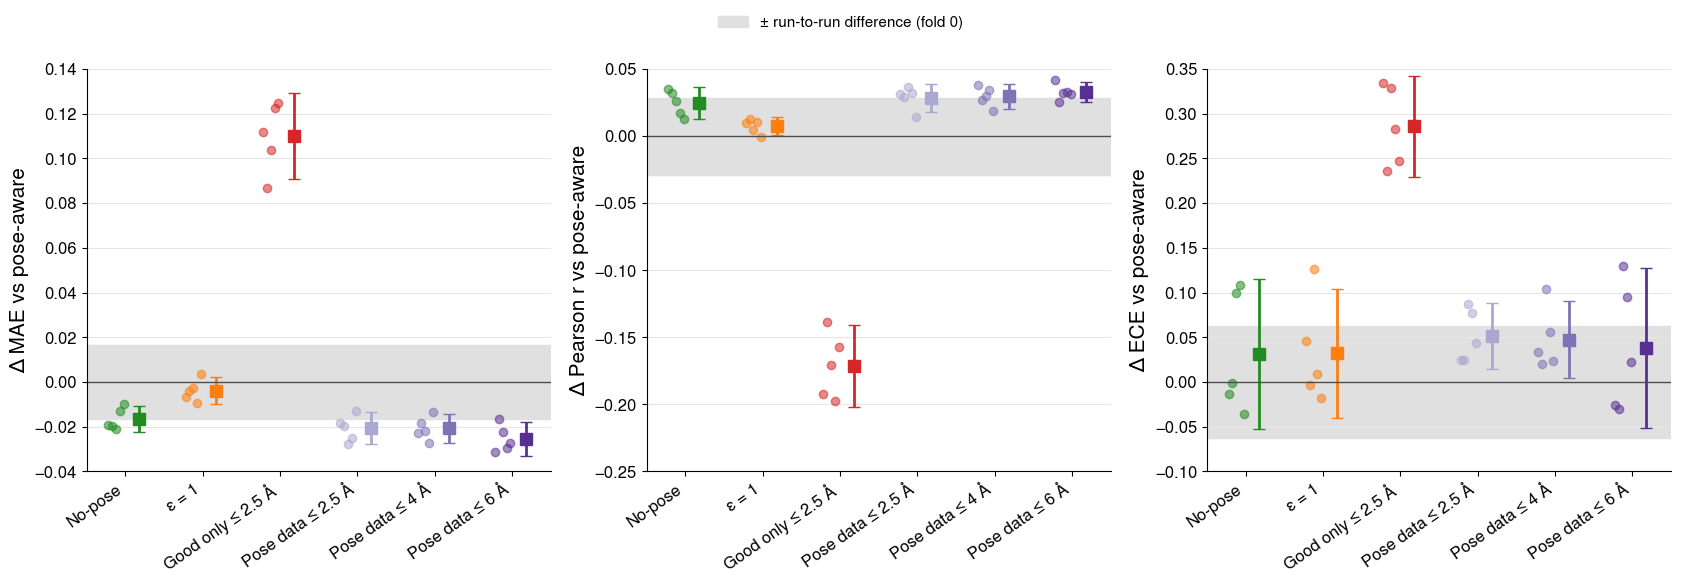

In [7]:
ORDER = ["no_pose"] + ARMS
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, metric in zip(axes, ["MAE", "Pearson r", "ECE"]):
    pt = paired_ref[paired_ref.metric == metric].set_index("model")
    for i, m in enumerate(ORDER):
        r = pt.loc[m]
        d = np.array([r[f"Δ fold {k}"] for k in range(K_FOLDS)], dtype=float)
        ax.plot(i - 0.12 + np.linspace(-0.1, 0.1, K_FOLDS), d, "o", color=MODELS[m]["color"], alpha=0.55, ms=6)
        ax.errorbar(i + 0.18, r["mean Δ"], yerr=[[r["mean Δ"] - r["95% CI low"]], [r["95% CI high"] - r["mean Δ"]]],
                    fmt="s", color=MODELS[m]["color"], capsize=4, ms=8)
    ax.axhspan(-abs(run_to_run[metric]), abs(run_to_run[metric]), color="0.88", zorder=0, label="± run-to-run difference (fold 0)")
    ax.axhline(0, color="0.3", lw=1)
    ax.set(xticks=range(len(ORDER)), xlim=(-0.5, len(ORDER) - 0.5), ylabel=f"Δ {metric} vs pose-aware")
    ax.set_xticklabels([MODELS[m]["label"] for m in ORDER], rotation=35, ha="right")
    ax.grid(True, axis="y", color="0.9")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.savefig(OUTPUT / "paired_differences_vs_pose_aware.png", dpi=600, bbox_inches="tight")
plt.show()

## Pose-quality range series

Pose supervision restricted to poses with true RMSD ≤ 2.5 / 4 / 6 / 10 Å (10 Å = the pose-aware model); activity data unchanged (≤ 10 Å), ε = 0.10. Grey lines: one fold each (paired); markers: mean ± sd over the folds; green dashed: no-pose mean.

**How to read this series.** A pose head trained on a restricted range cannot predict a low q: at ≤ 2.5 Å every target is q ≥ 0.86 by construction, and with a cutoff of 6 Å or less no training pose has the target of a bad pose (q ≤ 0.2 corresponds to RMSD ≥ 6.04 Å). The pose class weights (10 for q ≤ 0.2, 7 for q ≥ 0.8, 1 otherwise) then put 97 / 92 % of the pose loss on good poses at ≤ 4 / 6 Å, because the weight-10 class is absent. These models therefore predict a high q for almost every complex (none of the test poses is predicted bad, see the pose-head section below), so the weighting of the activity loss is nearly switched off. The series therefore compares a pose task on a narrow range, with almost no weighting, with the pose-aware model; ε = 1 is the model with the full pose task and no weighting.

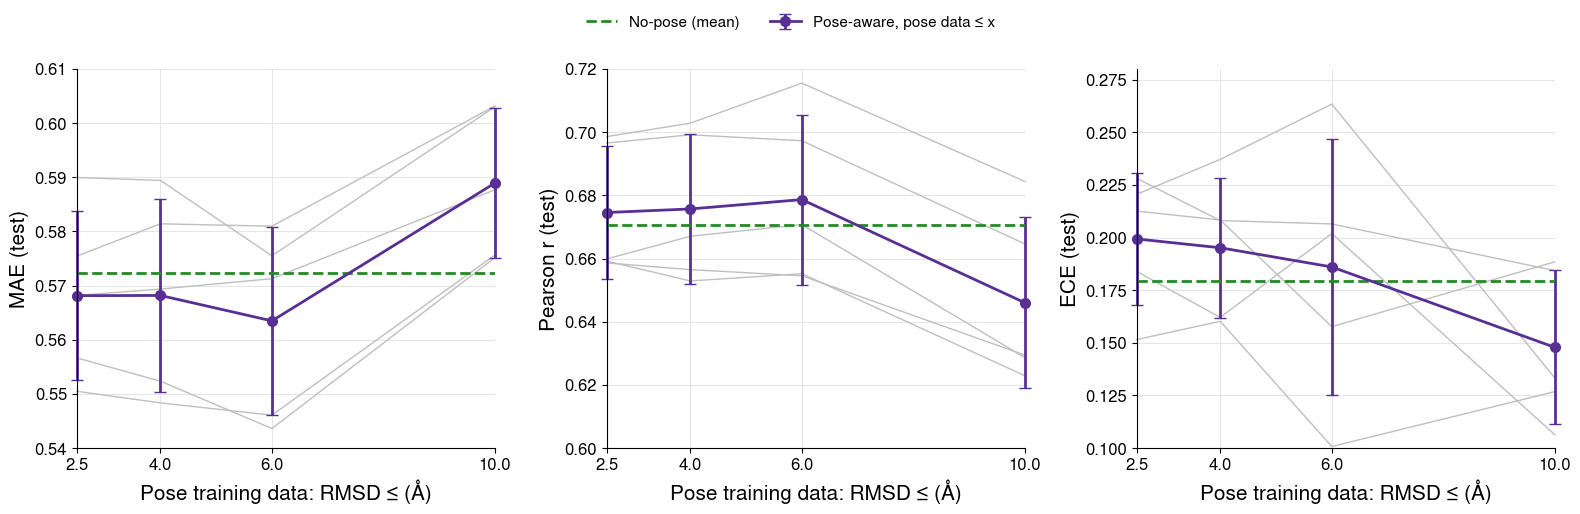

,model,metric,model mean,reference mean,mean Δ,95% CI low,95% CI high,folds model better
0,pose_data_2.5A,MAE,0.568,0.589,-0.021,-0.028,-0.014,5/5
1,pose_data_2.5A,RMSE,0.740,0.762,-0.021,-0.029,-0.014,5/5
2,pose_data_2.5A,Pearson r,0.675,0.646,0.029,0.018,0.039,5/5
3,pose_data_2.5A,ECE,0.199,0.148,0.051,0.015,0.088,0/5
4,pose_data_2.5A,|90% cov − 0.9|,0.121,0.084,0.037,0.004,0.070,0/5
5,pose_data_2.5A,"Spearman(σ, |e|)",0.233,0.217,0.016,-0.012,0.043,3/5
6,pose_data_4A,MAE,0.568,0.589,-0.021,-0.027,-0.014,5/5
7,pose_data_4A,RMSE,0.740,0.762,-0.022,-0.028,-0.016,5/5
8,pose_data_4A,Pearson r,0.676,0.646,0.030,0.020,0.039,5/5
9,pose_data_4A,ECE,0.195,0.148,0.047,0.004,0.090,0/5


In [8]:
xs = [x for _, x in SERIES]; cols = [m for m, _ in SERIES]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, metric in zip(axes, ["MAE", "Pearson r", "ECE"]):
    pf = per_fold.pivot(index="fold", columns="model", values=metric)
    for k, row in pf[cols].iterrows():
        ax.plot(xs, row.values, "-", color="0.75", lw=1, clip_on=False)
    mean, sd = pf[cols].mean(), pf[cols].std()
    ax.errorbar(xs, mean, yerr=sd, fmt="o-", color=plt.cm.Purples(0.85), capsize=4, ms=7, label="Pose-aware, pose data ≤ x", clip_on=False)
    ax.axhline(pf["no_pose"].mean(), color=COLORS["no_pose"], ls="--", label="No-pose (mean)")
    ax.set(xticks=xs, xlim=(2.5, 10), xlabel="Pose training data: RMSD ≤ (Å)", ylabel=f"{metric} (test)")
    ax.grid(True, color="0.9")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
fig.savefig(OUTPUT / "pose_range_series.png", dpi=600, bbox_inches="tight")
plt.show()
display(paired_table(per_fold, "pose_aware", [m for m, _ in SERIES], LOWER_BETTER)[
    ["model", "metric", "model mean", "reference mean", "mean Δ", "95% CI low", "95% CI high", "folds model better"]].round(3))

## Calibration plots

Folds pooled; 10 equal-count bins of σ; RMSE against mean σ per bin, in z-units (as Fig. 7 of the paper). Each panel compares one model with the pose-aware model.

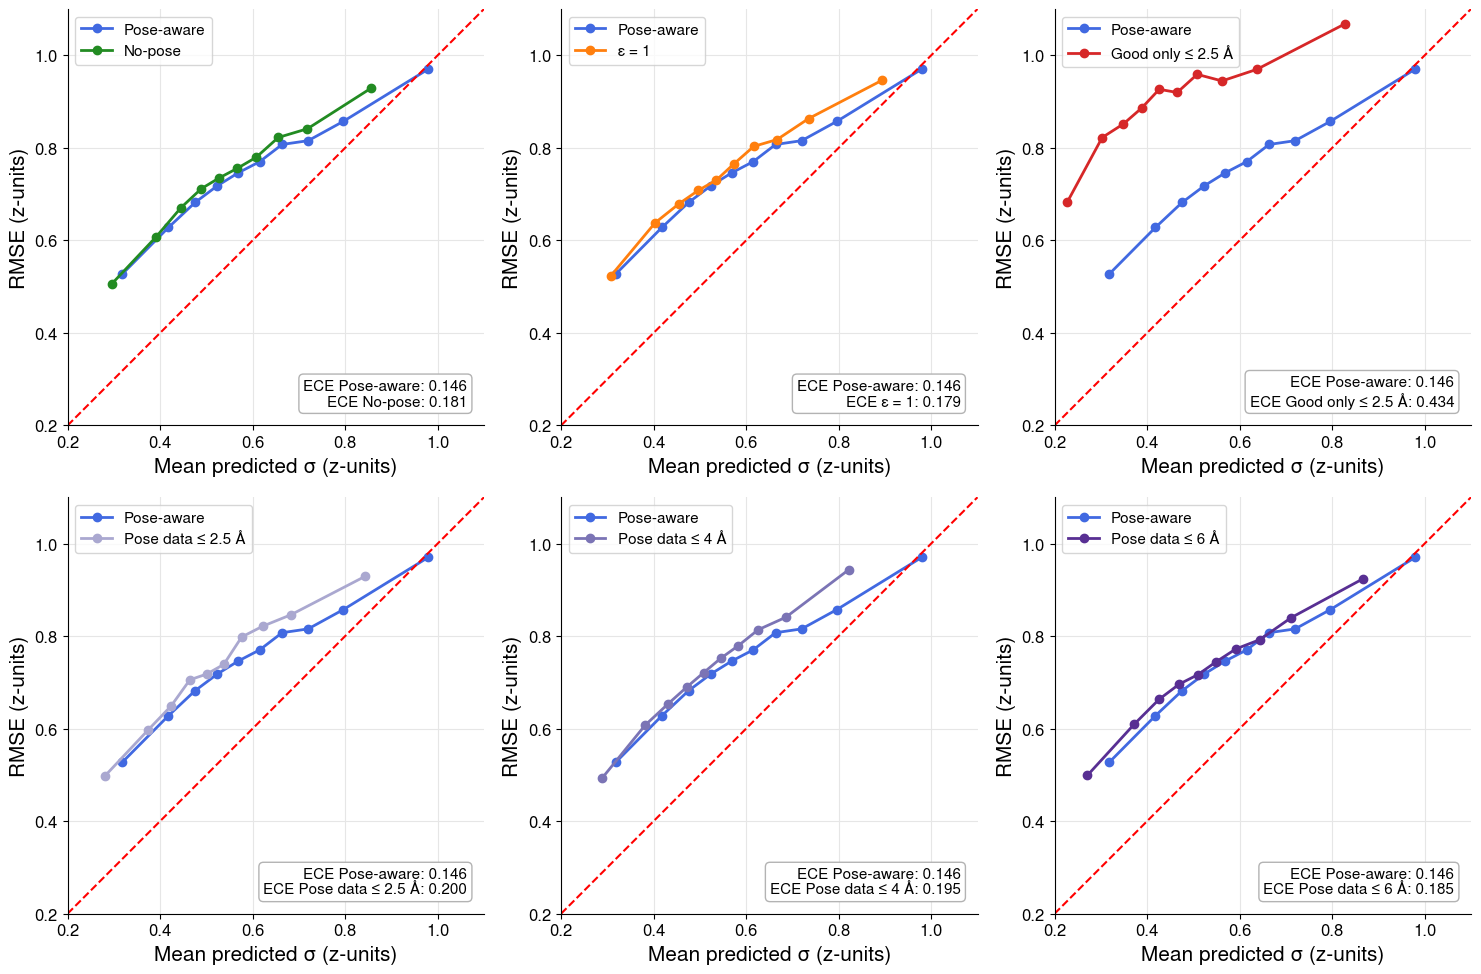

In [9]:
curves = {m: sigma_bins(pooled[m]) for m in MODELS}
vals = np.concatenate([np.r_[t.s, t.rmse] for t in curves.values()])
lo, hi = np.floor(vals.min() * 10) / 10, np.ceil(vals.max() * 10) / 10
panels = ["no_pose"] + ARMS
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, m in zip(axes.flat, panels):
    for mm in ["pose_aware", m]:
        t = curves[mm]
        ax.plot(t.s, t.rmse, "o-", color=MODELS[mm]["color"], label=MODELS[mm]["label"])
    ax.plot([lo, hi], [lo, hi], "--", color=COLORS["diagonal"], lw=1.5)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Mean predicted σ (z-units)", ylabel="RMSE (z-units)")
    ax.set_aspect("equal")
    ax.grid(True, color="0.9")
    ax.legend(loc="upper left")
    ax.text(0.96, 0.04, f"ECE {MODELS['pose_aware']['label']}: {ece(pooled['pose_aware']):.3f}\nECE {MODELS[m]['label']}: {ece(pooled[m]):.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=11,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.7"))
fig.tight_layout()
fig.savefig(OUTPUT / "calibration.png", dpi=600)
plt.show()

## Pose head on the cross-docked pose test set

Same test poses in every model; true RMSD to the crystal pose. Pose MAE and Pearson r on q (as in the paper), Spearman(q, true RMSD), AUROC of q for good (≤ 2.96 Å) vs bad (≥ 6.04 Å) poses, and the fraction of test poses predicted good / bad. The pose-range models never see poses above their cutoff in training, so their q is expected to lose resolution above it.

In [10]:
rows = []
for (m, k), p in test_pose.items():
    good, bad = p.target_pose >= GOOD_Q, p.target_pose <= BAD_Q
    sel = (good | bad).to_numpy()
    rows.append({"model": m, "fold": k, "n": len(p), "MAE pose": (p.pred_pose - p.target_pose).abs().mean(),
                 "Pearson pose": np.corrcoef(p.pred_pose, p.target_pose)[0, 1],
                 "Spearman(q, true RMSD)": stats.spearmanr(p.pred_pose, p.rmsd).correlation,
                 "AUROC q good vs bad": auroc(p.pred_pose.to_numpy()[sel], good.to_numpy()[sel]),
                 "fraction predicted good": (p.pred_pose >= GOOD_Q).mean(), "fraction predicted bad": (p.pred_pose <= BAD_Q).mean(),
                 "fraction truly good": good.mean(), "fraction truly bad": bad.mean()})
pose_fold = pd.DataFrame(rows)
pose_fold.to_csv(OUTPUT / "pose_metrics_per_fold.csv", index=False)
PCOLS = ["MAE pose", "Pearson pose", "Spearman(q, true RMSD)", "AUROC q good vs bad", "fraction predicted good", "fraction predicted bad", "fraction truly good", "fraction truly bad"]
agg = pose_fold.groupby("model", sort=False)[PCOLS].agg(["mean", "std"])
display(pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in PCOLS},
                     index=agg.index).rename(index=lambda m: MODELS[m]["label"]))
paired_pose = paired_table(pose_fold, "pose_aware", [m for m in MODELS if MODELS[m]["pose_task"]],
                           {"MAE pose": True, "Pearson pose": False, "AUROC q good vs bad": False})
paired_pose.to_csv(OUTPUT / "paired_pose_vs_pose_aware.csv", index=False)
paired_pose[["model", "metric", "model mean", "reference mean", "mean Δ", "95% CI low", "95% CI high", "folds model better"]].round(3)

,MAE pose,Pearson pose,"Spearman(q, true RMSD)",AUROC q good vs bad,fraction predicted good,fraction predicted bad,fraction truly good,fraction truly bad
model,,,,,,,,
Pose-aware,0.296 ± 0.011,0.373 ± 0.073,-0.357 ± 0.114,0.730 ± 0.073,0.198 ± 0.093,0.176 ± 0.073,0.459 ± 0.027,0.280 ± 0.035
ε = 1,0.292 ± 0.016,0.378 ± 0.052,-0.369 ± 0.079,0.733 ± 0.043,0.204 ± 0.056,0.158 ± 0.076,0.459 ± 0.027,0.280 ± 0.035
Good only ≤ 2.5 Å,0.370 ± 0.033,0.081 ± 0.042,-0.123 ± 0.052,0.550 ± 0.022,1.000 ± 0.000,0.000 ± 0.000,0.459 ± 0.027,0.280 ± 0.035
Pose data ≤ 2.5 Å,0.368 ± 0.033,0.085 ± 0.047,-0.120 ± 0.055,0.549 ± 0.032,1.000 ± 0.000,0.000 ± 0.000,0.459 ± 0.027,0.280 ± 0.035
Pose data ≤ 4 Å,0.357 ± 0.032,0.061 ± 0.082,-0.089 ± 0.127,0.529 ± 0.053,0.995 ± 0.008,0.000 ± 0.000,0.459 ± 0.027,0.280 ± 0.035
Pose data ≤ 6 Å,0.326 ± 0.031,0.246 ± 0.054,-0.284 ± 0.053,0.649 ± 0.040,0.670 ± 0.104,0.000 ± 0.000,0.459 ± 0.027,0.280 ± 0.035


,model,metric,model mean,reference mean,mean Δ,95% CI low,95% CI high,folds model better
0,eps_1,MAE pose,0.292,0.296,-0.004,-0.024,0.017,3/5
1,eps_1,Pearson pose,0.378,0.373,0.006,-0.060,0.071,2/5
2,eps_1,AUROC q good vs bad,0.733,0.730,0.003,-0.047,0.053,2/5
3,good_only_2.5A,MAE pose,0.370,0.296,0.075,0.028,0.122,0/5
4,good_only_2.5A,Pearson pose,0.081,0.373,-0.292,-0.422,-0.161,0/5
5,good_only_2.5A,AUROC q good vs bad,0.550,0.730,-0.180,-0.287,-0.072,0/5
6,pose_data_2.5A,MAE pose,0.368,0.296,0.073,0.025,0.121,0/5
7,pose_data_2.5A,Pearson pose,0.085,0.373,-0.288,-0.411,-0.164,0/5
8,pose_data_2.5A,AUROC q good vs bad,0.549,0.730,-0.181,-0.288,-0.074,0/5
9,pose_data_4A,MAE pose,0.357,0.296,0.062,0.016,0.108,0/5


Mean predicted q per 0.5 Å bin of the true RMSD (folds pooled), against the training target q(RMSD) (red dashed). Shading: good (≤ 2.96 Å) and bad (≥ 6.04 Å) poses.

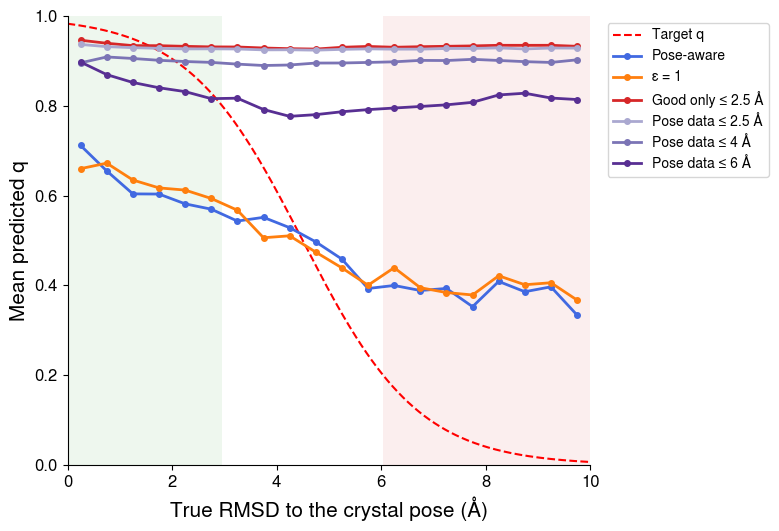

In [11]:
bins = np.arange(0, 10.01, 0.5)
centers = (bins[:-1] + bins[1:]) / 2
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axvspan(0, 2.96, color=COLORS["good"], alpha=0.08, lw=0)
ax.axvspan(6.04, 10, color=COLORS["bad"], alpha=0.08, lw=0)
r = np.linspace(0, 10, 300)
ax.plot(r, 1 / (1 + np.exp(K_SIG * (r - X0_SIG))), "--", color=COLORS["diagonal"], lw=1.5, label="Target q")
for m in MODELS:
    if not MODELS[m]["pose_task"]:
        continue
    p = pd.concat([test_pose[m, k] for k in range(K_FOLDS)])
    y = p.groupby(pd.cut(p.rmsd, bins), observed=False)["pred_pose"].mean().to_numpy()
    ax.plot(centers, y, "o-", ms=4, color=MODELS[m]["color"], label=MODELS[m]["label"])
ax.set(xlim=(0, 10), ylim=(0, 1), xlabel="True RMSD to the crystal pose (Å)", ylabel="Mean predicted q")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT / "pose_q_vs_true_rmsd.png", dpi=600)
plt.show()

## Does σ follow the predicted pose quality?

The predicted uncertainty of the pose-aware model is larger for complexes it predicts to have bad poses. Does this survive without the weighting (ε = 1) or with a narrower pose supervision? Each activity test complex is assigned a pose class from the **pose-aware** model's predicted q (good q ≥ 0.8, bad q ≤ 0.2), the same complexes for all models. AUROC of σ for bad vs good complexes (the probability that a bad complex has a larger σ than a good one; 0.5 = no separation) and the ratio of the mean σ of bad and good complexes, per fold, paired against the pose-aware model.

The classes come from the pose-aware model itself, so this shows whether σ follows the model's own pose prediction, not the true pose quality; the response of σ to the true RMSD of cross-docked poses is analysed in `pose_reliability_validation.ipynb`.

In [12]:
rows = []
for (m, k), d in test.items():
    q = test["pose_aware", k]["pose"].to_numpy()   # pose-aware model's predicted q, same complexes in every model
    good, bad = d.loc[q >= GOOD_Q, "sigma"].to_numpy(), d.loc[q <= BAD_Q, "sigma"].to_numpy()
    rows.append({"model": m, "fold": k, "AUROC σ bad vs good": auroc(np.r_[good, bad], np.r_[np.zeros(len(good)), np.ones(len(bad))]),
                 "mean σ good": good.mean(), "mean σ bad": bad.mean(), "σ bad / σ good": bad.mean() / good.mean()})
sig_cls = pd.DataFrame(rows)
sig_cls.to_csv(OUTPUT / "sigma_by_pose_class_per_fold.csv", index=False)
SCOLS = ["AUROC σ bad vs good", "mean σ good", "mean σ bad", "σ bad / σ good"]
agg = sig_cls.groupby("model", sort=False)[SCOLS].agg(["mean", "std"])
display(pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " + agg[c]["std"].map("{:.3f}".format) for c in SCOLS},
                     index=agg.index).rename(index=lambda m: MODELS[m]["label"]))
paired_sig = paired_table(sig_cls, "pose_aware", list(MODELS), {"AUROC σ bad vs good": False, "σ bad / σ good": False})
paired_sig.to_csv(OUTPUT / "paired_sigma_by_class.csv", index=False)
paired_sig[["model", "metric", "model mean", "reference mean", "mean Δ", "95% CI low", "95% CI high", "folds model better"]].round(3)

,AUROC σ bad vs good,mean σ good,mean σ bad,σ bad / σ good
model,,,,
Pose-aware,0.787 ± 0.038,0.526 ± 0.034,0.727 ± 0.032,1.383 ± 0.052
No-pose,0.569 ± 0.047,0.539 ± 0.047,0.575 ± 0.049,1.068 ± 0.051
ε = 1,0.583 ± 0.037,0.548 ± 0.053,0.592 ± 0.036,1.085 ± 0.052
Good only ≤ 2.5 Å,0.548 ± 0.031,0.459 ± 0.041,0.484 ± 0.035,1.055 ± 0.034
Pose data ≤ 2.5 Å,0.570 ± 0.034,0.514 ± 0.022,0.550 ± 0.016,1.071 ± 0.036
Pose data ≤ 4 Å,0.570 ± 0.043,0.518 ± 0.027,0.553 ± 0.014,1.070 ± 0.047
Pose data ≤ 6 Å,0.587 ± 0.045,0.521 ± 0.058,0.568 ± 0.040,1.095 ± 0.068


,model,metric,model mean,reference mean,mean Δ,95% CI low,95% CI high,folds model better
0,no_pose,AUROC σ bad vs good,0.569,0.787,-0.219,-0.260,-0.177,0/5
1,no_pose,σ bad / σ good,1.068,1.383,-0.315,-0.373,-0.257,0/5
2,eps_1,AUROC σ bad vs good,0.583,0.787,-0.204,-0.251,-0.157,0/5
3,eps_1,σ bad / σ good,1.085,1.383,-0.298,-0.378,-0.218,0/5
4,good_only_2.5A,AUROC σ bad vs good,0.548,0.787,-0.239,-0.269,-0.209,0/5
5,good_only_2.5A,σ bad / σ good,1.055,1.383,-0.327,-0.376,-0.279,0/5
6,pose_data_2.5A,AUROC σ bad vs good,0.570,0.787,-0.218,-0.234,-0.201,0/5
7,pose_data_2.5A,σ bad / σ good,1.071,1.383,-0.311,-0.358,-0.264,0/5
8,pose_data_4A,AUROC σ bad vs good,0.570,0.787,-0.217,-0.234,-0.200,0/5
9,pose_data_4A,σ bad / σ good,1.070,1.383,-0.313,-0.352,-0.274,0/5


### With each model's own predicted pose classes

The same AUROC with the classes taken from each model's **own** predicted q. Only the pose-aware and the ε = 1 model predict enough bad complexes for this; the pose-range and good-only models classify (almost) no test complex as bad, so their own-class AUROC is not defined (NaN) or rests on a handful of complexes. The ε = 1 model has a pose head as good as the pose-aware model's, so the comparison tests whether its σ follows its own pose prediction.

In [13]:
rows = []
for (m, k), d in test.items():
    if not MODELS[m]["pose_task"]:
        continue
    q = d["pose"].to_numpy()   # the model's own predicted q
    good, bad = d.loc[q >= GOOD_Q, "sigma"].to_numpy(), d.loc[q <= BAD_Q, "sigma"].to_numpy()
    rows.append({"model": m, "fold": k, "n good": len(good), "n bad": len(bad),
                 "AUROC σ bad vs good (own classes)": auroc(np.r_[good, bad], np.r_[np.zeros(len(good)), np.ones(len(bad))])})
own = pd.DataFrame(rows)
own.to_csv(OUTPUT / "sigma_by_own_pose_class_per_fold.csv", index=False)
tab = own.groupby("model", sort=False).agg(**{"AUROC σ bad vs good (own classes)": ("AUROC σ bad vs good (own classes)", "mean"),
                                              "sd": ("AUROC σ bad vs good (own classes)", "std"),
                                              "n good per fold": ("n good", "mean"), "n bad per fold": ("n bad", "mean")})
tab.insert(0, "AUROC σ bad vs good (pose-aware classes)", sig_cls.groupby("model")["AUROC σ bad vs good"].mean().reindex(tab.index))
tab.rename(index=lambda m: MODELS[m]["label"]).round(3)

,AUROC σ bad vs good (pose-aware classes),AUROC σ bad vs good (own classes),sd,n good per fold,n bad per fold
model,,,,,
Pose-aware,0.787,0.787,0.038,2689.4,1476.0
ε = 1,0.583,0.582,0.039,2927.4,1539.0
Good only ≤ 2.5 Å,0.548,NaN,NaN,12012.2,0.0
Pose data ≤ 2.5 Å,0.570,NaN,NaN,12012.8,0.0
Pose data ≤ 4 Å,0.570,NaN,NaN,11996.0,0.0
Pose data ≤ 6 Å,0.587,0.800,0.283,9765.2,0.4
